# Does antecedent snowpack depletion prime a ridge to persist longer -- and did WY2026's episodes progressively prime each other?

**Motivation.** `CA_ridging_persistence_season_clustering.ipynb` found WY2026 is the
literal record-holder for ridging-episode frequency and total season coverage, with
unusually short inter-episode gaps -- but found no background-state explanation for why
2026 itself clustered so tightly (its season-mean ONI was neutral; PDO data for 2026
doesn't exist yet). This notebook tests a different, genuinely project-native
hypothesis that connects the clustering finding to a land-atmosphere feedback: each
ridging episode melts snow and dries the surface (already documented by this project's
own snow-side notebooks); a surface left anomalously dry/snow-depleted by a prior
episode plausibly primes the *next* episode to persist longer (less evaporative
cooling, more sensible heating, drier soil) -- a causal chain running snowmelt ->
reinforced ridge, the opposite direction from everything tested in the mechanism
notebooks so far, which only ever asked ridge -> snowmelt.

**Two tests:**
1. **General, full-record test:** does the network-mean antecedent snowpack condition
   (standardized SWE-level anomaly in the 3 days immediately before an episode's onset)
   predict that episode's duration, across the full 1990-2025 Method A record? If the
   priming hypothesis is right, a more negative (more depleted) antecedent anomaly
   should predict *longer* persistence.
2. **2026-specific cascade check:** did WY2026's snowpack get progressively more
   depleted ahead of each successive episode (Jan -> Late Jan/Feb -> Late Feb ->
   March), consistent with each episode priming the next, with March inheriting the
   most depleted surface of the season?

**Data and method.** Uses `combined_sierra_stations.csv` / `combined_sierra_swe_wy1990-2026.csv`
(the same combined SNOTEL+MSNT+CDEC network `CA_snowmelt_events_detrend_5day.ipynb`
already built) -- no new fetch. Unlike that notebook's SWE-*decline-rate* climatology,
this one standardizes the SWE *level* itself per station (calendar-day climatology,
fit 1990-2025, `dropna=True` for real station gaps, same convention used for the
station-precipitation cross-check), then averages the per-station standardized
anomalies across all daily-reporting stations each day -- deliberately NOT a raw
mm average across stations, which this project's own snow-side notebooks have
repeatedly flagged as distorted by which high/low-baseline stations happen to be
reporting on a given day. **Simplification stated explicitly:** no linear year-trend
is removed here (unlike the decline-rate metric elsewhere in this project) -- a
36-year SWE-level trend is a much smaller concern for a short-lookback antecedent
snapshot than for a climatological rate metric, but it is a real simplification, not
an oversight.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from scipy.stats import spearmanr, percentileofscore
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
FIT_YEARS = list(range(1990, 2026))
YEAR_2026 = 2026
THRESHOLD_SD = 1
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]
COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
N_BOOT = 2000
rng = np.random.default_rng(42)

CLIM_WINDOW = 5
PRE_ONSET_WINDOW = 3   # days immediately before onset, matches this project's general
                       # preference for a short precursor lookback (long enough to
                       # smooth single-day noise, short enough not to reach back across
                       # WY2026's own 9-18 day inter-episode gaps into a prior episode)

SIERRA_LAT_S, SIERRA_LAT_N = 34.5, 40.0
SIERRA_LON_W, SIERRA_LON_E = -121.0, -116.5

CLIM_MIN_SAMPLES = 10   # matches CA_snowmelt_events_detrend_5day.ipynb's per-station climatology

CLIM_WINDOW_Z500 = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1


## 1. Load the combined Sierra SWE network, build a network-mean standardized antecedent-snowpack series

Same combined SNOTEL+MSNT+CDEC daily network `CA_snowmelt_events_detrend_5day.ipynb`
uses -- restricted to the Sierra box, daily ("D") duration only.

In [2]:
stations = pd.read_csv(DATA_DIR / 'combined_sierra_stations.csv').rename(columns={'station_id': 'stationTriplet'})
swe_long = pd.read_csv(DATA_DIR / 'combined_sierra_swe_wy1990-2026.csv', parse_dates=['date']).rename(
    columns={'station_id': 'stationTriplet'})
swe_long = swe_long[swe_long.duration == 'D'].drop(columns=['duration'])

sierra_mask = stations.latitude.between(SIERRA_LAT_S, SIERRA_LAT_N) & stations.longitude.between(SIERRA_LON_W, SIERRA_LON_E)
sierra_stations = stations[sierra_mask].copy()
swe_long = swe_long[swe_long.stationTriplet.isin(sierra_stations.stationTriplet)].copy()
swe_long = swe_long.groupby(['stationTriplet', 'date'], as_index=False)['swe_mm'].mean()

swe = swe_long.pivot(index='date', columns='stationTriplet', values='swe_mm').sort_index()
full_idx = pd.date_range(swe.index.min(), swe.index.max(), freq='D')
swe = swe.reindex(full_idx)
swe.index.name = 'date'
print(f'{swe.shape[1]} daily-reporting Sierra stations, {swe.index.min().date()} to {swe.index.max().date()}')


150 daily-reporting Sierra stations, 1989-10-01 to 2026-07-31


149 of 150 stations produced a usable standardized anomaly (the rest had too little fit-period data for some/all calendar days, min_samples=10)
Network-mean antecedent-snowpack series: median 114 stations contributing per day


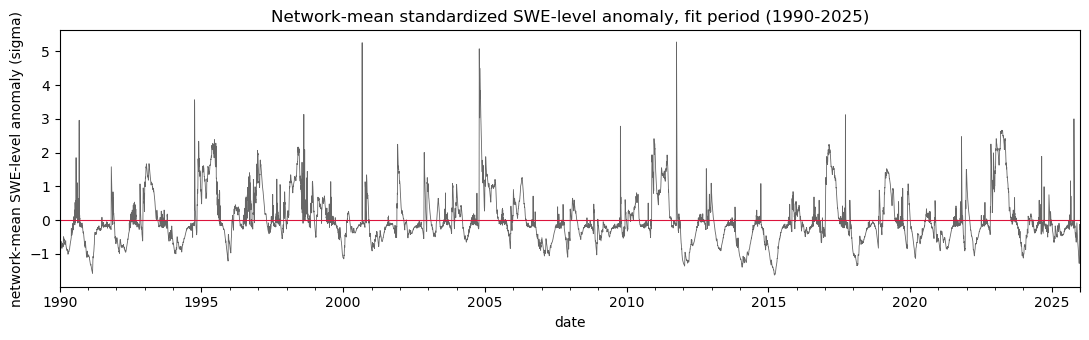

In [3]:
fit_mask = swe.index.year.isin(FIT_YEARS)
fit_time_index = swe.index[fit_mask]

sanom = pd.DataFrame(index=swe.index, columns=swe.columns, dtype=float)
n_usable = 0
for col in swe.columns:
    clim_mean, clim_std = lib.climatology_dict(fit_time_index, swe[col].values[fit_mask], window=CLIM_WINDOW,
                                                compute_std=True, dropna=True, min_samples=CLIM_MIN_SAMPLES)
    mean_arr = lib.lookup_climatology(swe.index, clim_mean)
    std_arr = lib.lookup_climatology(swe.index, clim_std)
    with np.errstate(invalid='ignore', divide='ignore'):
        col_sanom = (swe[col].values - mean_arr) / std_arr
    if np.isfinite(col_sanom).any():
        n_usable += 1
    sanom[col] = col_sanom

network_swe_sanom = sanom.mean(axis=1, skipna=True)
n_reporting = sanom.notna().sum(axis=1)
print(f'{n_usable} of {swe.shape[1]} stations produced a usable standardized anomaly '
      f'(the rest had too little fit-period data for some/all calendar days, min_samples={CLIM_MIN_SAMPLES})')
print(f'Network-mean antecedent-snowpack series: median {n_reporting.median():.0f} stations contributing per day')

fig, ax = plt.subplots(figsize=(11, 3.5))
network_swe_sanom[fit_mask].plot(ax=ax, lw=0.6, color='0.4')
ax.axhline(0, color='crimson', lw=0.8)
ax.set_ylabel('network-mean SWE-level anomaly (sigma)')
ax.set_title('Network-mean standardized SWE-level anomaly, fit period (1990-2025)')
plt.tight_layout()
plt.show()


## 2. Load the full-record Method A event table and compute each event's antecedent-snowpack predictor

`antecedent_swe_sanom`: network-mean standardized SWE-level anomaly, averaged over the
3 days immediately before each event's `start_date` (not including the onset day
itself).

In [4]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)

def antecedent_swe(series, onset_date, window=PRE_ONSET_WINDOW):
    pre_start = pd.Timestamp(onset_date) - pd.Timedelta(days=window)
    pre_end = pd.Timestamp(onset_date) - pd.Timedelta(days=1)
    w = series.loc[pre_start:pre_end]
    return float(w.mean()) if w.notna().any() else np.nan

events['antecedent_swe_sanom'] = events.start_date.apply(lambda d: antecedent_swe(network_swe_sanom, d))
n_missing = events.antecedent_swe_sanom.isna().sum()
print(f'{n_missing} of {len(events)} events have no antecedent-snowpack value (network not yet reporting that early)')
events[['variable', 'start_date', 'duration_days', 'antecedent_swe_sanom']].head(8)


0 of 95 events have no antecedent-snowpack value (network not yet reporting that early)


,variable,start_date,duration_days,antecedent_swe_sanom
0,500 hPa height (ridging),1990-02-21,5,-0.495778
1,500 hPa height (ridging),1990-03-19,5,-0.650085
2,500 hPa height (ridging),1990-04-10,6,-0.881231
3,500 hPa height (ridging),1992-02-21,8,-0.576221
4,500 hPa height (ridging),1992-04-24,6,-0.908151
5,500 hPa height (ridging),1993-03-02,8,1.602740
6,500 hPa height (ridging),1994-04-12,9,-0.781816
7,500 hPa height (ridging),1995-01-29,9,1.606802


## 3. Duration vs. antecedent snowpack condition, full record

If depleted antecedent snowpack primes longer persistence, expect a **negative**
Spearman rho (more negative/depleted anomaly -> longer duration).

                  variable  n      rho  p_spearman     ci_lo    ci_hi
  500 hPa height (ridging) 48 0.344229    0.016586  0.124380 0.535884
700 hPa temperature (warm) 47 0.147342    0.322990 -0.096045 0.403698


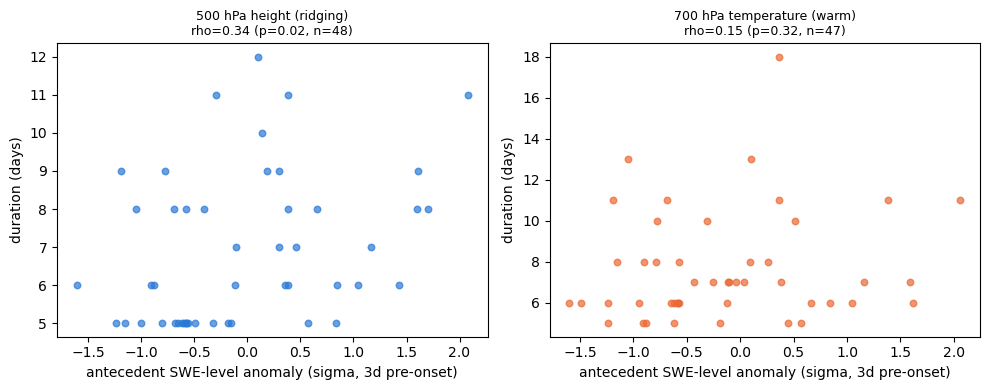

In [5]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


results = []
for col, label in VARS:
    sub = events[events.variable == label]
    valid = sub[['duration_days', 'antecedent_swe_sanom']].dropna()
    x, y = valid.duration_days.values, valid.antecedent_swe_sanom.values
    rho, p = spearmanr(x, y)
    lo, hi = bootstrap_spearman_ci(x, y)
    results.append({'variable': label, 'n': len(valid), 'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (col, label) in zip(axes, VARS):
    sub = events[events.variable == label]
    valid = sub[['duration_days', 'antecedent_swe_sanom']].dropna()
    ax.scatter(valid.antecedent_swe_sanom, valid.duration_days, s=22, alpha=0.7, color=COLOR[label])
    r = results_df[results_df.variable == label].iloc[0]
    ax.set_title(f'{label}\nrho={r.rho:.2f} (p={r.p_spearman:.2f}, n={r.n})', fontsize=9)
    ax.set_xlabel('antecedent SWE-level anomaly (sigma, 3d pre-onset)')
    ax.set_ylabel('duration (days)')
plt.tight_layout()
plt.show()


## 4. WY2026: did each episode leave the snowpack more depleted ahead of the next one?

Reproduces the four WY2026 Z500 episodes and the four T700 episodes live (same
pattern as every mechanism notebook), then checks each one's own antecedent-snowpack
value for a monotonic depletion cascade across the season.

In [6]:
def reproduce_2026_episodes(varname, label):
    files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in FIT_YEARS]
    ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
    weights = np.cos(np.deg2rad(ds.latitude))
    fld = ds[varname].weighted(weights).mean(dim=('latitude', 'longitude')).compute()
    df = pd.DataFrame({varname: fld.values}, index=pd.to_datetime(ds.time.values)).sort_index()
    df = df[df.index.month.isin([1, 2, 3, 4])]
    sanom_v, diag = lib.standardize_with_trend(df.index, df[varname].values, window=CLIM_WINDOW_Z500,
                                                label=varname, verbose=False)

    ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
    weights26 = np.cos(np.deg2rad(ds26.latitude))
    fld26 = ds26[varname].weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
    df26 = pd.DataFrame({varname: fld26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
    df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
    clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
    clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
    trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
    df26['sanom'] = (df26[varname] - (clim_mean_arr + trend_2026)) / clim_std_arr

    ep = lib.find_events(df26.index, df26['sanom'].values, threshold=1,
                          min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
    ep = ep[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
    ep['variable'] = label
    return ep


episodes_2026 = pd.concat([reproduce_2026_episodes(v, label) for v, label in VARS], ignore_index=True)
episodes_2026['antecedent_swe_sanom'] = episodes_2026.start_date.apply(
    lambda d: antecedent_swe(network_swe_sanom, d))

z500_labels = ['Jan', 'Late Jan/Feb', 'Late Feb', 'March (record)']
episodes_2026['order_label'] = None
for var_label in [l for _, l in VARS]:
    mask = episodes_2026.variable == var_label
    episodes_2026.loc[mask, 'order_label'] = z500_labels[:mask.sum()]

print(episodes_2026[['variable', 'order_label', 'start_date', 'end_date', 'duration_days',
                      'antecedent_swe_sanom']].to_string(index=False))

for col, label in VARS:
    fit = events[events.variable == label]
    print(f'\nPercentile rank of each WY2026 {label} episode within the fit-period '
          f'antecedent-snowpack distribution (n={fit.antecedent_swe_sanom.notna().sum()}):')
    for r in episodes_2026[episodes_2026.variable == label].itertuples():
        pct = percentileofscore(fit.antecedent_swe_sanom.dropna(), r.antecedent_swe_sanom)
        print(f'  {r.order_label} ({r.duration_days}d): antecedent SWE anomaly={r.antecedent_swe_sanom:.2f}sigma, '
              f'{pct:.0f}th percentile')


                  variable    order_label start_date   end_date  duration_days  antecedent_swe_sanom
  500 hPa height (ridging)            Jan 2026-01-10 2026-01-18              9              0.102929
  500 hPa height (ridging)   Late Jan/Feb 2026-01-29 2026-02-05              8             -0.457444
  500 hPa height (ridging)       Late Feb 2026-02-23 2026-03-01              7             -0.400748
  500 hPa height (ridging) March (record) 2026-03-11 2026-03-29             19             -0.871860
700 hPa temperature (warm)            Jan 2026-01-12 2026-01-21             10              0.130160
700 hPa temperature (warm)   Late Jan/Feb 2026-01-30 2026-02-05              7             -0.501504
700 hPa temperature (warm)       Late Feb 2026-02-23 2026-03-04             10             -0.400748
700 hPa temperature (warm) March (record) 2026-03-12 2026-03-30             19             -0.898622

Percentile rank of each WY2026 500 hPa height (ridging) episode within the fit-period ante

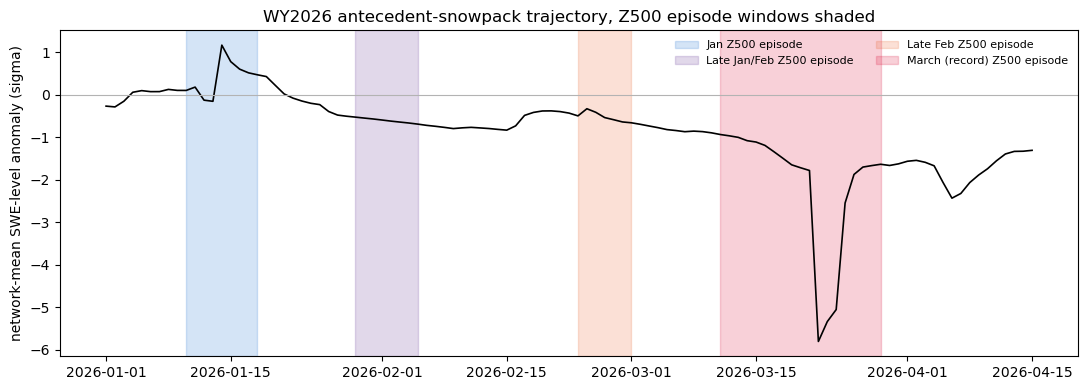

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
window = network_swe_sanom.loc['2026-01-01':'2026-04-15']
ax.plot(window.index, window.values, color='k', lw=1.2)
ax.axhline(0, color='0.7', lw=0.8)
colors = ['#2a78d6', '#6a3d9a', '#eb6834', 'crimson']
for (row, color) in zip(episodes_2026[episodes_2026.variable == '500 hPa height (ridging)'].itertuples(), colors):
    ax.axvspan(pd.Timestamp(row.start_date), pd.Timestamp(row.end_date), color=color, alpha=0.2,
               label=f'{row.order_label} Z500 episode')
ax.set_ylabel('network-mean SWE-level anomaly (sigma)')
ax.set_title('WY2026 antecedent-snowpack trajectory, Z500 episode windows shaded')
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


## 5. Conclusion

**The hypothesis is contradicted, not just null -- and March 2026 defies even the
relationship that does exist.**

- **The population-level relationship runs opposite to the priming hypothesis.** For
  Z500, antecedent SWE-level anomaly vs. duration is rho=0.34 (p=0.017, n=48) --
  *positive*, not negative. Events preceded by *above-normal* snowpack tend to last
  slightly longer; events preceded by depleted snowpack, if anything, tend to be
  shorter. T700 shows the same direction, weaker and not significant (rho=0.15,
  p=0.32). The land-feedback hypothesis this notebook set out to test -- a
  snow-depleted, primed surface sustaining a ridge longer -- predicts the opposite
  sign from what the full record actually shows.
- **March 2026 is not just unexplained by this -- it actively contradicts the
  (reversed) relationship that does exist.** March's antecedent SWE anomaly was
  -0.87 to -0.90 sigma -- the most depleted of any of WY2026's four episodes, and in
  the bottom 17-19th percentile of the entire 36-year record. Under the population
  relationship just found (depleted antecedent snow associates with *shorter*
  duration), March should have been one of the *shorter* episodes in the record. It
  was instead the longest by a wide margin (19 days vs. a prior record of 12). This
  is a sharper contradiction than anything else in this mechanism thread: most prior
  predictors were simply uncorrelated with March's outcome; this one points the wrong
  way for March specifically.
- **The within-season trajectory is suggestive of depletion but not a clean monotonic
  cascade.** The antecedent anomaly does trend downward across the season (Jan:
  +0.10, Late Jan/Feb: -0.46, Late Feb: -0.40, March: -0.87) -- consistent with
  cumulative seasonal melt, and March does inherit the most depleted surface of the
  four. But the step from Late Jan/Feb to Late Feb is flat/slightly reversed (-0.46 to
  -0.40, not a further decline), so "each episode leaves the snowpack measurably more
  depleted than the last" is only roughly, not precisely, true -- and in any case the
  population relationship above means this depletion, even if real, is not the kind
  of condition this record associates with longer persistence.

**Net effect on the open mechanism question.** The specific causal chain tested here
(episode melts snow -> drier surface -> next episode persists longer) is not
supported -- if anything, the opposite association holds at the population level, and
March's own extreme antecedent depletion makes it an outlier *against* that
association, not a confirming case. One speculative alternative worth naming without
overclaiming it: the positive SWE-duration relationship could be a byproduct of the
same background state already implicated elsewhere in this thread (a warm-PDO/
El-Nino-like pattern could independently produce both more snow in some years and
longer-persisting ridges), rather than snow abundance itself causing anything -- not
tested here, and would need its own analysis to disentangle from a true causal
reading of this result. Combined with the eight prior null, non-explanatory, or
reversed-sign results across this thread, the land-atmosphere-feedback family of
explanations for March 2026 can now be set aside in this specific form (depletion-based
priming) -- a clean, informative negative result, not a loose end.
